# 04 – Classification model: is the train late (≥ 3 min)?
**Approach**
1. Temporal train/test split (the last ~30% of the days as test set → realistic, no “look into the future”)
2. Compare a baseline, a logistic regression and a random forest
3. Measures of fit: accuracy, precision, recall, F1, ROC-AUC (not only accuracy because of the class imbalance!)
4. **Beyond pure prediction:** separate models for *German-speaking Switzerland vs. Romandy* and *peak vs. off-peak* → do model quality and the most important factors differ?
5. Interpretation with a logit model (odds ratios, p-values)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Database:", config.DB_PATH.relative_to(ROOT))
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from src.features import load_analysis, temporal_split, NUM_FEATURES, CAT_FEATURES, BIN_FEATURES

MAX_TRAIN = 300_000   # training sample (computing time); increase if needed
df = load_analysis(conn)
train, test, test_days = temporal_split(df)
print(f"Train: {len(train):,} rows | Test: {len(test):,} rows | test days: {test_days[0]} to {test_days[-1]}")
print(f"Share late – train: {train['late'].mean():.1%}, test: {test['late'].mean():.1%}")

Database: data/train_delays.sqlite


Train: 278,024 rows | Test: 122,111 rows | test days: 2026-10-24 to 2026-10-27
Share late – train: 6.6%, test: 5.5%


In [2]:
def make_preprocessor(cat, num_bin):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", StandardScaler(), num_bin),
    ])

def evaluate(name, model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = model.predict(X)
    return {"Model": name,
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba) if len(np.unique(y)) > 1 else np.nan}

def sample(d, n):
    return d.sample(n, random_state=config.RANDOM_STATE) if len(d) > n else d

FEATURES = CAT_FEATURES + NUM_FEATURES + BIN_FEATURES
tr = sample(train, MAX_TRAIN)
X_tr, y_tr = tr[FEATURES], tr["late"]
X_te, y_te = test[FEATURES], test["late"]

## 1. Train and compare models
`class_weight="balanced"`: late trains are the minority – without weighting the model would almost always predict “on time”.

In [3]:
models = {
    "Baseline (always on time)": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                                           ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random forest": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                               ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                                              class_weight="balanced_subsample", n_jobs=-1,
                                                              random_state=config.RANDOM_STATE))]),
}
results = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    results.append(evaluate(name, m, X_te, y_te))
results = pd.DataFrame(results).set_index("Model")
display(results.style.format("{:.3f}"))
results.round(3).to_csv(config.OUTPUT_DIR / "04_model_comparison.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (always on time),0.945,0.000,0.000,0.000,0.500
Logistic regression,0.698,0.090,0.491,0.153,0.643
Random forest,0.801,0.115,0.388,0.178,0.679


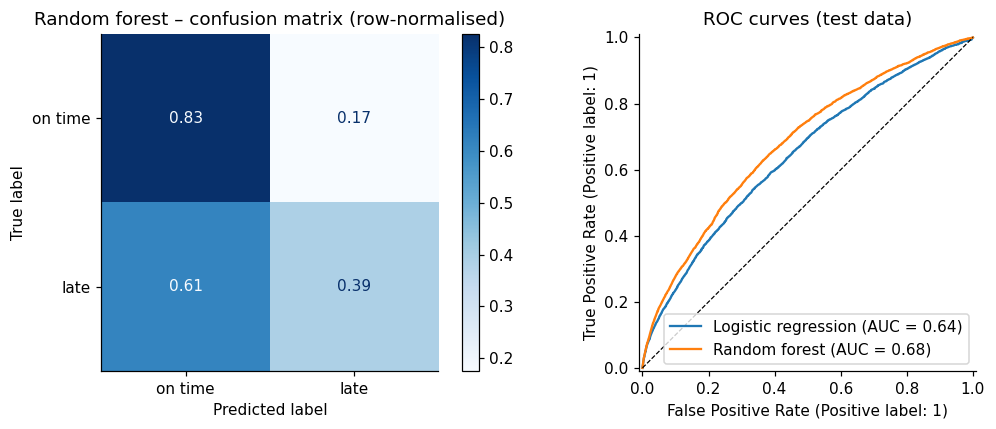

In [4]:
rf = models["Random forest"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, rf.predict(X_te), normalize="true"),
                       display_labels=["on time", "late"]).plot(ax=axes[0], cmap="Blues", values_format=".2f")
axes[0].set_title("Random forest – confusion matrix (row-normalised)")
for name in ["Logistic regression", "Random forest"]:
    RocCurveDisplay.from_estimator(models[name], X_te, y_te, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_title("ROC curves (test data)")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "04_confusion_roc.png", dpi=200); plt.show()

## 2. Group comparison: do the influencing factors differ?
A separate random forest is trained for each group (without the group variable itself). The **permutation importance** shows how much the model quality (ROC-AUC) drops when a feature is randomly shuffled.

In [5]:
groups = {
    "German-speaking": ("region", "German-speaking"),
    "Romandy":         ("region", "Romandy"),
    "Peak":            ("time_window", "Peak"),
    "Off-peak":        ("time_window", "Off-peak"),
}
group_metrics, importances = [], {}
for gname, (col, value) in groups.items():
    tr_g, te_g = train[train[col] == value], test[test[col] == value]
    if len(tr_g) < 1000 or te_g["late"].nunique() < 2:
        print(f"{gname}: too little data – skipped"); continue
    drop = {"region": ["region"], "time_window": ["peak"]}[col]
    cat = [c for c in CAT_FEATURES if c not in drop]
    num = [c for c in NUM_FEATURES + BIN_FEATURES if c not in drop]
    tr_g = sample(tr_g, MAX_TRAIN)
    m = Pipeline([("prep", make_preprocessor(cat, num)),
                  ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                                 class_weight="balanced_subsample", n_jobs=-1,
                                                 random_state=config.RANDOM_STATE))])
    m.fit(tr_g[cat + num], tr_g["late"])
    group_metrics.append({"Group": gname, "n_train": len(tr_g), "n_test": len(te_g),
                          "Share late (test)": te_g["late"].mean(),
                          **{k: v for k, v in evaluate(gname, m, te_g[cat + num], te_g["late"]).items() if k != "Model"}})
    te_s = sample(te_g, 20_000)
    pi = permutation_importance(m, te_s[cat + num], te_s["late"], scoring="roc_auc",
                                n_repeats=5, random_state=config.RANDOM_STATE, n_jobs=-1)
    importances[gname] = pd.Series(pi.importances_mean, index=cat + num)

group_metrics = pd.DataFrame(group_metrics).set_index("Group")
display(group_metrics.style.format({"n_train": "{:,}", "n_test": "{:,}", "Share late (test)": "{:.1%}",
                                    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
                                    "F1": "{:.3f}", "ROC-AUC": "{:.3f}"}))
group_metrics.round(3).to_csv(config.OUTPUT_DIR / "04_group_comparison.csv")

,n_train,n_test,Share late (test),Accuracy,Precision,Recall,F1,ROC-AUC
Group,,,,,,,,
German-speaking,"223,517","97,944",5.1%,0.826,0.116,0.365,0.176,0.681
Romandy,"43,995","19,541",7.9%,0.745,0.135,0.410,0.203,0.650
Peak,"73,605","21,178",7.1%,0.886,0.116,0.093,0.103,0.585
Off-peak,"204,419","100,933",5.2%,0.767,0.111,0.498,0.182,0.696


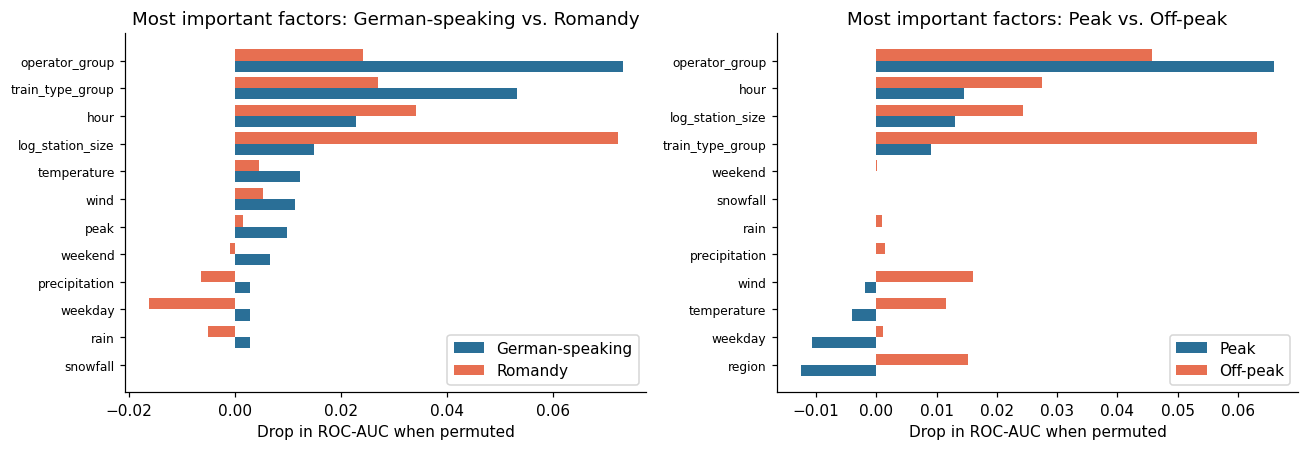

,German-speaking,Romandy,Peak,Off-peak
hour,0.0228,0.0342,0.0146,0.0276
log_station_size,0.0149,0.0721,0.0130,0.0243
operator_group,0.0730,0.0241,0.0660,0.0457
peak,0.0097,0.0016,NaN,NaN
precipitation,0.0029,-0.0064,0.0000,0.0014
rain,0.0028,-0.0050,0.0000,0.0010
region,NaN,NaN,-0.0125,0.0152
snowfall,0.0000,0.0000,0.0000,0.0000
temperature,0.0122,0.0045,-0.0041,0.0115
train_type_group,0.0531,0.0269,0.0091,0.0632


In [6]:
imp = pd.DataFrame(importances)
pairs = [("German-speaking", "Romandy"), ("Peak", "Off-peak")]
pairs = [p for p in pairs if all(x in imp.columns for x in p)]
fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 4.2), squeeze=False)
for ax, (a, b) in zip(axes[0], pairs):
    sub = imp[[a, b]].dropna().sort_values(a)
    y = np.arange(len(sub))
    ax.barh(y - 0.2, sub[a], height=0.4, label=a, color="#2a6f97")
    ax.barh(y + 0.2, sub[b], height=0.4, label=b, color="#e76f51")
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=8)
    ax.set_xlabel("Drop in ROC-AUC when permuted"); ax.set_title(f"Most important factors: {a} vs. {b}"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "04_feature_importance_groups.png", dpi=200); plt.show()
display(imp.round(4))

## 3. Interpretation with a logistic regression (statsmodels)
Odds ratio > 1 → higher odds of a delay. The interaction term `region × peak` directly tests whether the effect of peak hours in Romandy differs from the one in German-speaking Switzerland.

In [7]:
import statsmodels.formula.api as smf

d = sample(df[df["region"].isin(["German-speaking", "Romandy"])], 200_000).copy()
formula = ("late ~ C(region, Treatment('German-speaking')) * peak + weekend"
           " + precipitation + temperature + wind + C(train_type_group, Treatment('S-Bahn')) + log_station_size")
logit = smf.logit(formula, data=d).fit(disp=False)
or_tab = pd.DataFrame({"Odds ratio": np.exp(logit.params), "CI 2.5%": np.exp(logit.conf_int()[0]),
                       "CI 97.5%": np.exp(logit.conf_int()[1]), "p-value": logit.pvalues})
display(or_tab.style.format({"Odds ratio": "{:.3f}", "CI 2.5%": "{:.3f}", "CI 97.5%": "{:.3f}", "p-value": "{:.4f}"}))
print(f"Pseudo R² (McFadden): {logit.prsquared:.3f}")
or_tab.round(4).to_csv(config.OUTPUT_DIR / "04_logit_odds_ratios.csv")

,Odds ratio,CI 2.5%,CI 97.5%,p-value
Intercept,0.012,0.009,0.015,0.0000
"C(region, Treatment('German-speaking'))[T.Romandy]",1.727,1.617,1.844,0.0000
"C(train_type_group, Treatment('S-Bahn'))[T.InterCity]",2.026,1.904,2.157,0.0000
"C(train_type_group, Treatment('S-Bahn'))[T.InterRegio]",1.332,1.261,1.408,0.0000
"C(train_type_group, Treatment('S-Bahn'))[T.International]",6.777,6.143,7.475,0.0000
"C(train_type_group, Treatment('S-Bahn'))[T.Other]",2.729,2.273,3.277,0.0000
"C(train_type_group, Treatment('S-Bahn'))[T.Regio]",1.168,1.075,1.268,0.0002
"C(train_type_group, Treatment('S-Bahn'))[T.RegioExpress]",1.115,1.032,1.204,0.0061
peak,1.672,1.594,1.753,0.0000
"C(region, Treatment('German-speaking'))[T.Romandy]:peak",0.596,0.539,0.658,0.0000


Pseudo R² (McFadden): 0.035


## 4. Interpretation

*(Real data, training 14–23 Oct, test 24–27 Oct)*
- **Model quality:** the baseline reaches 94.5% accuracy but does not detect a single late train → accuracy is misleading here. The **random forest** is the best model (ROC-AUC 0.68, recall 0.39, precision 0.12, F1 0.18), ahead of the logistic regression (ROC-AUC 0.64). The model therefore detects about 4 in 10 delays but raises many false alarms. With timetable, train and weather features, delays can only be predicted **moderately well**; much depends on events that are not recorded (disruptions, knock-on delays).
- **Most important factors overall:** operator and train type, followed by the hour and the station size. Weather plays a minor role.
- **German-speaking Switzerland vs. Romandy:** in German-speaking Switzerland, the operator (SBB vs. regional railways) and the train type dominate. In Romandy, the **station size** is the most important factor (large hubs such as Lausanne with 12.2% late are clearly less punctual), followed by the hour.
- **Peak vs. off-peak:** off-peak, the train type is decisive; during peak hours it is the operator. The peak model is weak (ROC-AUC 0.59); the test days include a weekend, so the test set contains only 2 working days with peak hours.
- **Logit model (odds ratios, all p < 0.01):** in German-speaking Switzerland, peak hours increase the odds of a delay by a **factor of 1.67**. The interaction term Romandy × peak (OR 0.60) shows: **in Romandy, peak hours have practically no additional effect** (1.67 × 0.60 ≈ 1.0), but the base level is higher (OR 1.73). Further effects: precipitation OR 1.21 per mm/h, international trains OR 6.8 and InterCity OR 2.0 compared with the S-Bahn, weekend OR 0.77. Pseudo R² = 0.035 → the features explain only a small part of the variation.
- **Limitations:** only ~2 weeks in autumn (hardly any snow), region at canton level, weather at the arrival station (not along the route), knock-on delays not modelled, only 17 stations in Romandy.